# 01 — EDA : Détection d'anomalies fiscales
### Dataset : `data_FraudDetection_JAR2020.csv` (Bao, Ke, Li, Yu, Zhang — Journal of Accounting Research, 2020)

Objectif de ce notebook :
1. Charger et inspecter le dataset, avec des contrôles de qualité explicites
2. Examiner la variable cible `misstate` (déséquilibre de classes)
3. Analyser la distribution temporelle (`fyear`)
4. Détecter les valeurs manquantes
5. Statistiques descriptives des variables comptables et ratios
6. Comparer les distributions fraude vs non-fraude, avec un test statistique à l'appui
7. Matrice de corrélation

**Suite** : `02_feature_engineering.ipynb`

## 0. Imports et configuration

In [1]:
import sys
from pathlib import Path

# Rend `src/` importable quel que soit le répertoire de travail depuis lequel
# ce notebook est lancé (VS Code, JupyterLab, `jupyter nbconvert --execute`...),
# au lieu d'un chemin relatif codé en dur comme `"../data/raw/..."`.
sys.path.insert(0, str(Path.cwd().parent if (Path.cwd().parent / "src").exists() else Path.cwd()))

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import RAW_ACCOUNTING_VARS, RATIO_VARS, ID_VARS, DATA_RAW, FIGURES_DIR
from src.preprocessing import load_raw_data, check_duplicates
from src.viz import set_style, save_fig, COLOR_FRAUD, COLOR_NON_FRAUD

pd.set_option("display.max_columns", 100)
set_style()

## 1. Chargement et premier coup d'œil

On charge le CSV et on vérifie la forme générale du dataset : nombre de lignes/colonnes,
types de données, et on compare les colonnes présentes à celles attendues
(28 variables comptables + 14 ratios + `fyear`, `gvkey`, `p_aaer`, `misstate`).

`load_raw_data()` (dans `src/preprocessing.py`) lève une erreur explicite si le
fichier est absent, avec les instructions de téléchargement — plus utile qu'un
`FileNotFoundError` brut de pandas si `data/raw/` n'a pas été peuplé.

In [2]:
df = load_raw_data(DATA_RAW)

print("Shape :", df.shape)
df.head()

Shape : (146045, 46)


,fyear,gvkey,p_aaer,misstate,act,ap,at,ceq,che,cogs,csho,dlc,dltis,dltt,dp,ib,invt,ivao,ivst,lct,lt,ni,ppegt,pstk,re,rect,sale,sstk,txp,txt,xint,prcc_f,dch_wc,ch_rsst,dch_rec,dch_inv,soft_assets,ch_cs,ch_cm,ch_roa,issue,bm,dpi,reoa,EBIT,ch_fcf
0,1990,1009,NaN,0,10.047,3.736,32.335,6.262,0.002,30.633,2.526,3.283,32.853,17.691,1.971,1.431,2.355,0.000,0.000,8.382,26.073,2.135,31.767,0.000,5.420,6.895,40.522,0.000,0.000,0.769,2.333,6.000,0.069595,0.046043,0.041935,0.033034,0.312448,0.095082,0.082631,-0.019761,1,0.413170,0.873555,0.167620,0.161961,-0.042140
1,1990,1011,NaN,0,1.247,0.803,7.784,0.667,0.171,1.125,3.556,0.021,2.017,5.871,0.700,-1.869,0.663,0.132,0.000,1.246,7.117,-1.869,7.328,0.000,-3.339,0.290,3.635,0.006,0.000,0.000,0.640,1.188,-0.065604,-0.240937,-0.006248,-0.026684,0.315904,0.188832,-0.211389,-0.117832,1,0.157887,0.745139,-0.428957,-0.157888,0.100228
2,1990,1017,NaN,0,55.040,3.601,118.120,44.393,3.132,107.343,3.882,6.446,6.500,37.603,6.271,1.722,4.292,12.989,2.913,32.615,73.727,2.574,78.331,0.000,46.630,47.366,144.258,0.000,0.000,0.986,3.962,5.125,0.092822,0.020143,0.002156,0.002746,0.605342,0.097551,-0.105780,0.091206,1,2.231337,1.015131,0.394768,0.063681,0.066348
3,1990,1021,NaN,0,24.684,3.948,34.591,7.751,0.411,31.214,4.755,8.791,0.587,8.906,1.325,0.422,15.463,0.000,0.000,16.208,25.545,0.422,11.145,1.295,3.280,8.522,48.292,0.000,0.448,0.365,2.269,1.562,0.014060,0.035120,0.035583,0.008332,0.793068,-0.005725,-0.249704,0.017545,1,1.043582,1.026261,0.094822,0.088347,-0.017358
4,1990,1028,NaN,0,17.325,3.520,27.542,-12.142,1.017,32.662,6.735,32.206,0.000,0.266,2.711,-23.577,8.971,0.000,0.000,39.418,39.684,-22.812,5.782,0.000,-25.955,6.354,33.543,0.000,0.000,0.000,3.510,1.125,-0.540503,-0.575325,-0.102153,-0.222022,0.869182,-0.231536,-1.674893,-0.466667,0,-1.602508,0.598443,-0.942379,-0.700821,0.130349


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 146045 entries, 0 to 146044
Data columns (total 46 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   fyear        146045 non-null  int64  
 1   gvkey        146045 non-null  int64  
 2   p_aaer       964 non-null     float64
 3   misstate     146045 non-null  int64  
 4   act          146045 non-null  float64
 5   ap           146045 non-null  float64
 6   at           146045 non-null  float64
 7   ceq          146045 non-null  float64
 8   che          146045 non-null  float64
 9   cogs         146045 non-null  float64
 10  csho         146045 non-null  float64
 11  dlc          146045 non-null  float64
 12  dltis        146045 non-null  float64
 13  dltt         146045 non-null  float64
 14  dp           146045 non-null  float64
 15  ib           146045 non-null  float64
 16  invt         146045 non-null  float64
 17  ivao         146045 non-null  float64
 18  ivst         146045 non-null  float

In [4]:
expected_cols = set(ID_VARS + RAW_ACCOUNTING_VARS + RATIO_VARS)
actual_cols = set(df.columns)

print("Colonnes attendues mais absentes :", expected_cols - actual_cols)
print("Colonnes présentes mais non attendues :", actual_cols - expected_cols)
print("Nombre total de colonnes :", len(df.columns))

Colonnes attendues mais absentes : set()
Colonnes présentes mais non attendues : set()
Nombre total de colonnes : 46


### Contrôles de qualité des données

Deux vérifications qui ne coûtent rien et évitent des surprises silencieuses
plus tard dans le pipeline : l'unicité de la clé (entreprise, année fiscale),
et l'absence de valeurs manquantes en dehors de `p_aaer` et des ratios
dérivés (attendus, cf. section 4).

In [5]:
dup = check_duplicates(df)
print(f"Doublons sur (gvkey, fyear) : {len(dup)}")
assert dup.empty, "La clé (gvkey, fyear) devrait être unique — vérifier la source des données."

# Les 28 variables comptables brutes sont documentées comme 100% complètes
# (README, section Dataset) : on le vérifie plutôt que de le supposer.
raw_missing = df[RAW_ACCOUNTING_VARS].isnull().sum().sum()
print(f"Valeurs manquantes sur les 28 variables comptables brutes : {raw_missing}")
assert raw_missing == 0, "Les variables comptables brutes ne devraient pas contenir de NaN."
print("OK — clé unique, variables comptables brutes complètes.")

Doublons sur (gvkey, fyear) : 0
Valeurs manquantes sur les 28 variables comptables brutes : 0
OK — clé unique, variables comptables brutes complètes.


## 2. Examen de la variable cible `misstate`

C'est le point critique du projet : on quantifie le déséquilibre de classes,
qui conditionnera le choix des métriques (jamais l'accuracy seule) et des
techniques de rééquilibrage (SMOTE, class_weight, RUSBoost) plus tard.

In [6]:
counts = df["misstate"].value_counts()
pct = df["misstate"].value_counts(normalize=True) * 100

print("Effectifs :\n", counts)
print("\nPourcentages :\n", pct.round(3))

Effectifs :
 misstate
0    145081
1       964
Name: count, dtype: int64

Pourcentages :
 misstate
0    99.34
1     0.66
Name: proportion, dtype: float64


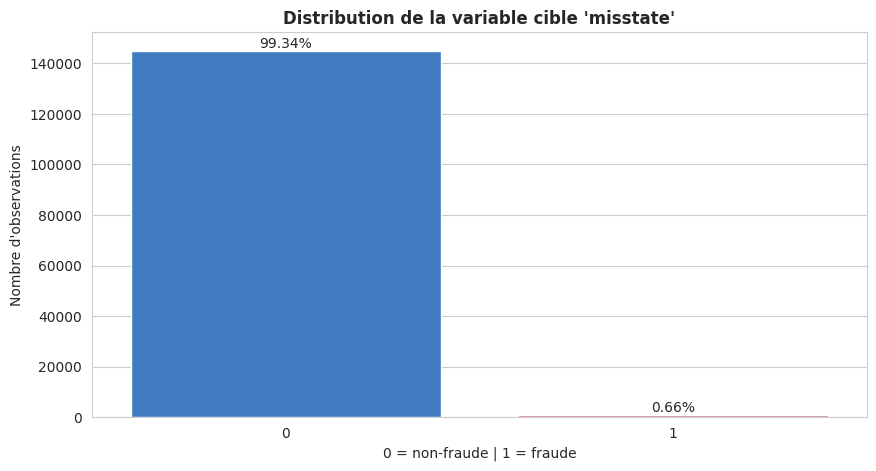

In [7]:
fig, ax = plt.subplots()
sns.countplot(x="misstate", data=df, hue="misstate",
              palette={0: COLOR_NON_FRAUD, 1: COLOR_FRAUD}, legend=False, ax=ax)
ax.set_title("Distribution de la variable cible 'misstate'")
ax.set_xlabel("0 = non-fraude | 1 = fraude")
ax.set_ylabel("Nombre d'observations")

for p, pc in zip(ax.patches, pct.sort_index()):
    ax.annotate(f"{pc:.2f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")

save_fig(fig, "01_target_distribution")
plt.show()

## 3. Distribution temporelle (`fyear`)

On regarde comment le nombre d'observations et le taux de fraude évoluent
dans le temps (1990–2014 environ). Cela guidera un split train/test **temporel**
plutôt qu'aléatoire, plus réaliste pour un cas d'usage d'audit fiscal.

In [8]:
yearly = df.groupby("fyear")["misstate"].agg(["count", "sum"])
yearly["fraud_rate_%"] = (yearly["sum"] / yearly["count"]) * 100
yearly.rename(columns={"count": "total_obs", "sum": "nb_fraud"}, inplace=True)
yearly

,total_obs,nb_fraud,fraud_rate_%
fyear,,,
1990,4582,15,0.327368
1991,4713,27,0.572884
1992,4970,26,0.523139
1993,5377,30,0.557932
1994,5684,23,0.404645
1995,6230,22,0.353130
1996,6745,33,0.489251
1997,6789,42,0.618648
1998,6716,56,0.833830


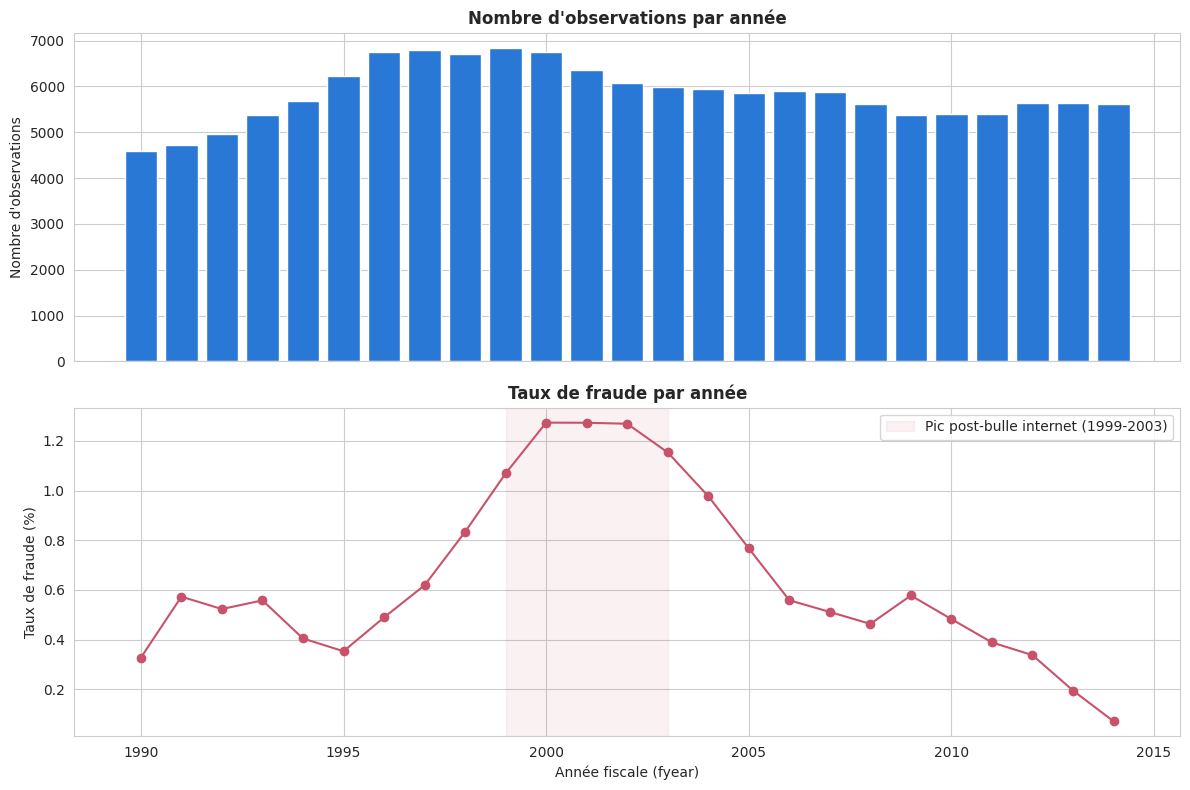

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].bar(yearly.index, yearly["total_obs"], color=COLOR_NON_FRAUD)
axes[0].set_ylabel("Nombre d'observations")
axes[0].set_title("Nombre d'observations par année")

axes[1].plot(yearly.index, yearly["fraud_rate_%"], marker="o", color=COLOR_FRAUD)
axes[1].axvspan(1999, 2003, color=COLOR_FRAUD, alpha=0.08,
                 label="Pic post-bulle internet (1999-2003)")
axes[1].set_ylabel("Taux de fraude (%)")
axes[1].set_xlabel("Année fiscale (fyear)")
axes[1].set_title("Taux de fraude par année")
axes[1].legend()

fig.tight_layout()
save_fig(fig, "02_temporal_fraud_rate")
plt.show()

## 4. Valeurs manquantes

On identifie les colonnes à problème. `p_aaer` est l'identifiant de l'AAER
(Accounting and Auditing Enforcement Release) : il est normalement vide (NaN)
pour les observations non-frauduleuses, donc un taux élevé de NaN est attendu
et n'est pas un problème de qualité de données.

In [10]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({"nb_missing": missing, "pct_missing": missing_pct})
missing_df[missing_df["nb_missing"] > 0]

,nb_missing,pct_missing
p_aaer,145081,99.34
ch_cm,17107,11.71
ch_cs,15918,10.90
ch_roa,12678,8.68
dpi,9228,6.32
ch_fcf,5407,3.70
ch_rsst,4851,3.32
dch_wc,4759,3.26
dch_rec,4743,3.25
dch_inv,4615,3.16


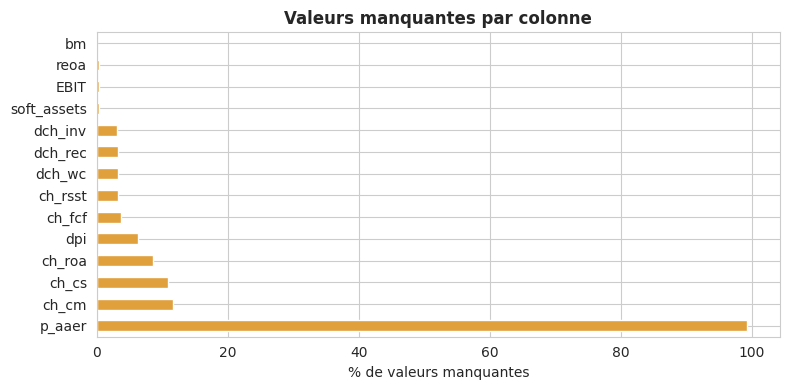

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
missing_df[missing_df["nb_missing"] > 0]["pct_missing"].plot(kind="barh", ax=ax, color="#e0a03c")
ax.set_xlabel("% de valeurs manquantes")
ax.set_title("Valeurs manquantes par colonne")
fig.tight_layout()
save_fig(fig, "03_missing_values")
plt.show()

## 5. Statistiques descriptives (variables comptables et ratios)

On repère les valeurs aberrantes (min/max très éloignés de la médiane) et les
échelles très différentes entre variables — ce qui justifiera une normalisation
(ou une transformation log) avant modélisation.

In [12]:
df[RAW_ACCOUNTING_VARS].describe().T

,count,mean,std,min,25%,50%,75%,max
act,146045.0,737.847759,3744.542368,-0.254,8.277,47.501,249.832,152629.000
ap,146045.0,181.993488,1047.546104,0.000,1.151,6.462,42.259,39903.000
at,146045.0,2374.041576,11957.736980,0.000,18.281,105.346,672.929,410074.000
ceq,146045.0,887.126243,5056.948150,-25560.000,6.337,47.308,271.547,284434.000
che,146045.0,218.657186,1330.490185,-34.000,1.144,9.373,60.286,85709.000
cogs,146045.0,1302.280756,7870.665783,-366.645,6.795,53.382,372.730,435726.253
csho,146045.0,97.004595,540.874888,0.000,8.796,22.540,60.736,100092.395
dlc,146045.0,127.228109,1023.091819,-0.069,0.008,1.363,12.750,75553.000
dltis,146045.0,201.312344,1628.477359,-19.687,0.000,0.063,24.873,188791.978
dltt,146045.0,538.377614,2660.670828,0.000,0.000,4.474,126.212,120274.000


In [13]:
df[RATIO_VARS].describe().T

,count,mean,std,min,25%,50%,75%,max
dch_wc,141286.0,-0.004899,0.181995,-0.999628,-0.032666,0.003573,0.044768,0.609004
ch_rsst,141194.0,0.018818,0.427313,-2.072079,-0.059976,0.026280,0.122151,1.504204
dch_rec,141302.0,0.013441,0.083445,-0.304659,-0.010005,0.005001,0.034544,0.382809
dch_inv,141430.0,0.007452,0.056766,-0.222022,-0.001819,0.000000,0.014791,0.268206
soft_assets,145453.0,0.499790,0.274129,0.004515,0.270023,0.524640,0.726663,0.993599
ch_cs,130127.0,0.185169,1.383354,-6.484197,-0.073635,0.067918,0.250237,9.600000
ch_cm,128938.0,-0.090980,2.844807,-17.359699,-0.260164,-0.023205,0.139960,16.573810
ch_roa,133367.0,-0.010208,0.379574,-1.671565,-0.058635,-0.001893,0.042188,1.621628
issue,146045.0,0.863487,0.343333,0.000000,1.000000,1.000000,1.000000,1.000000
bm,146027.0,0.466137,1.314661,-7.034304,0.191546,0.442172,0.805320,4.937457


## 6. Comparaison des distributions : fraude vs non-fraude

On compare visuellement quelques variables clés entre les deux groupes
(`misstate` = 0 vs 1) pour repérer celles qui semblent déjà discriminantes,
et on **quantifie** cette différence avec un test de Mann-Whitney U (test non
paramétrique, adapté à des distributions non gaussiennes et à des groupes de
taille très déséquilibrée — ici 964 fraudes contre 145 081 non-fraudes) plutôt
que de s'appuyer uniquement sur une lecture visuelle des boxplots.

Note : les boxplots utilisent des quantiles filtrés pour limiter l'effet des
valeurs extrêmes sur la lisibilité (le test statistique, lui, porte sur les
données complètes, non filtrées).

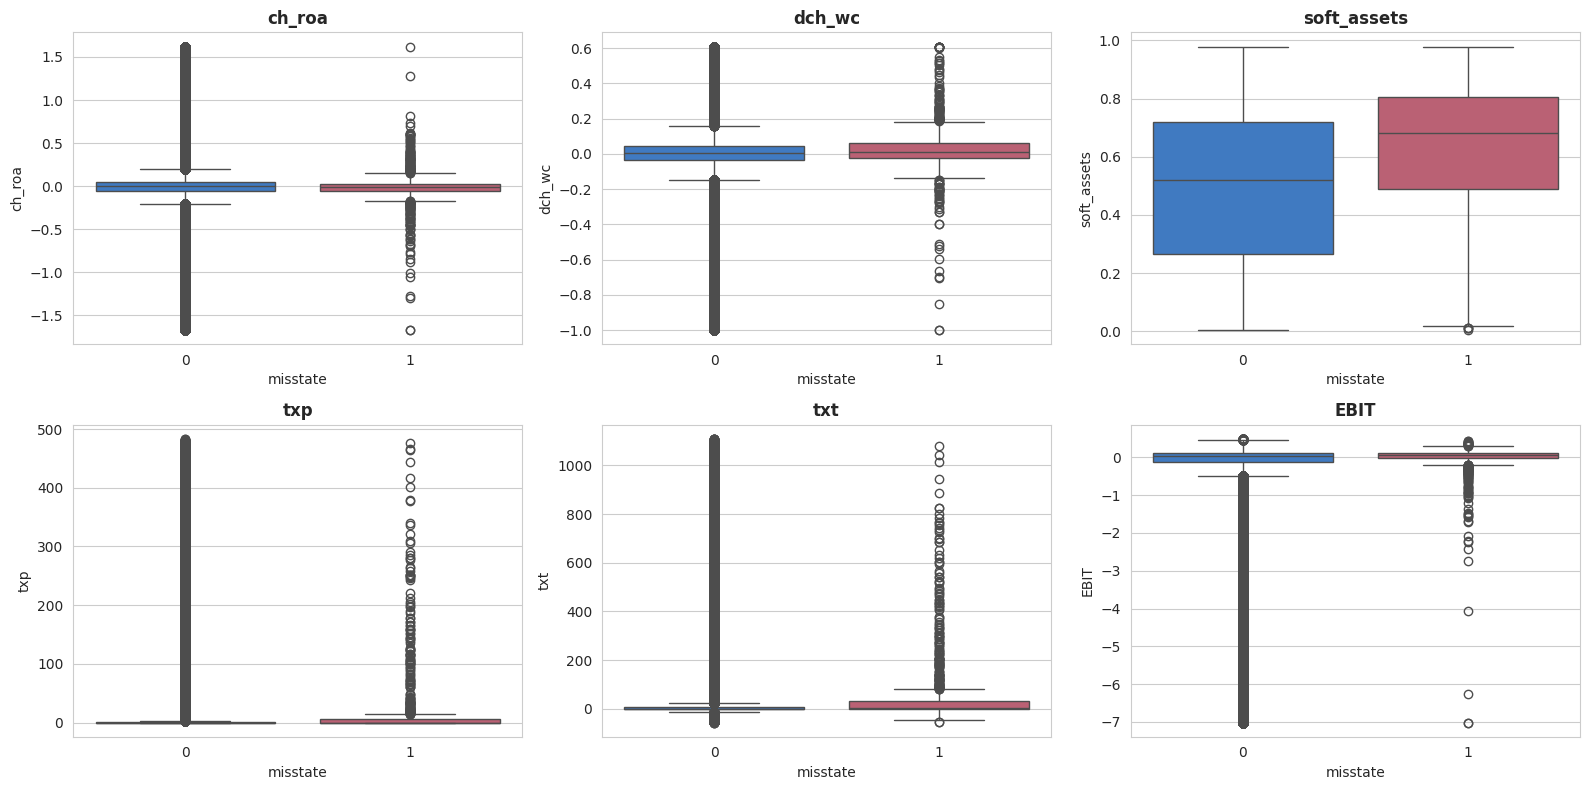

In [14]:
key_vars = ["ch_roa", "dch_wc", "soft_assets", "txp", "txt", "EBIT"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, var in enumerate(key_vars):
    lower, upper = df[var].quantile([0.01, 0.99])
    subset = df[(df[var] >= lower) & (df[var] <= upper)]

    sns.boxplot(x="misstate", y=var, data=subset, hue="misstate",
                palette={0: COLOR_NON_FRAUD, 1: COLOR_FRAUD}, legend=False, ax=axes[i])
    axes[i].set_title(var)
    axes[i].set_xlabel("misstate")

fig.tight_layout()
save_fig(fig, "04_fraud_vs_nonfraud_boxplots")
plt.show()

In [15]:
rows = []
for var in key_vars:
    fraud_vals = df.loc[df["misstate"] == 1, var].dropna()
    nonfraud_vals = df.loc[df["misstate"] == 0, var].dropna()

    u_stat, p_value = stats.mannwhitneyu(fraud_vals, nonfraud_vals, alternative="two-sided")
    # taille d'effet rank-biserial, indépendante de l'échelle de la variable
    effect_size = 1 - (2 * u_stat) / (len(fraud_vals) * len(nonfraud_vals))

    rows.append({
        "variable": var,
        "mean_fraud": fraud_vals.mean(),
        "mean_non_fraud": nonfraud_vals.mean(),
        "median_fraud": fraud_vals.median(),
        "median_non_fraud": nonfraud_vals.median(),
        "mannwhitney_p": p_value,
        "significatif_5%": p_value < 0.05,
        "rank_biserial_effect_size": effect_size,
    })

discriminant_vars = pd.DataFrame(rows).set_index("variable").round(4)
discriminant_vars.sort_values("rank_biserial_effect_size", key=abs, ascending=False)

,mean_fraud,mean_non_fraud,median_fraud,median_non_fraud,mannwhitney_p,significatif_5%,rank_biserial_effect_size
variable,,,,,,,
soft_assets,0.6348,0.4989,0.6839,0.5234,0.0000,True,-0.2875
txt,98.0538,54.9698,4.4365,0.3370,0.0000,True,-0.2116
txp,39.1009,23.6131,0.0285,0.0000,0.0000,True,-0.1433
EBIT,-0.0241,-0.2402,0.0642,0.0435,0.0000,True,-0.1272
dch_wc,0.0240,-0.0051,0.0106,0.0035,0.0000,True,-0.0813
ch_roa,-0.0126,-0.0102,-0.0048,-0.0019,0.2285,False,0.0230


## 7. Matrice de corrélation

On détecte la redondance entre variables (multicolinéarité) avant modélisation.
Les paires très corrélées (> 0.85) seront à surveiller, en particulier pour
des modèles sensibles à la colinéarité (régression logistique).

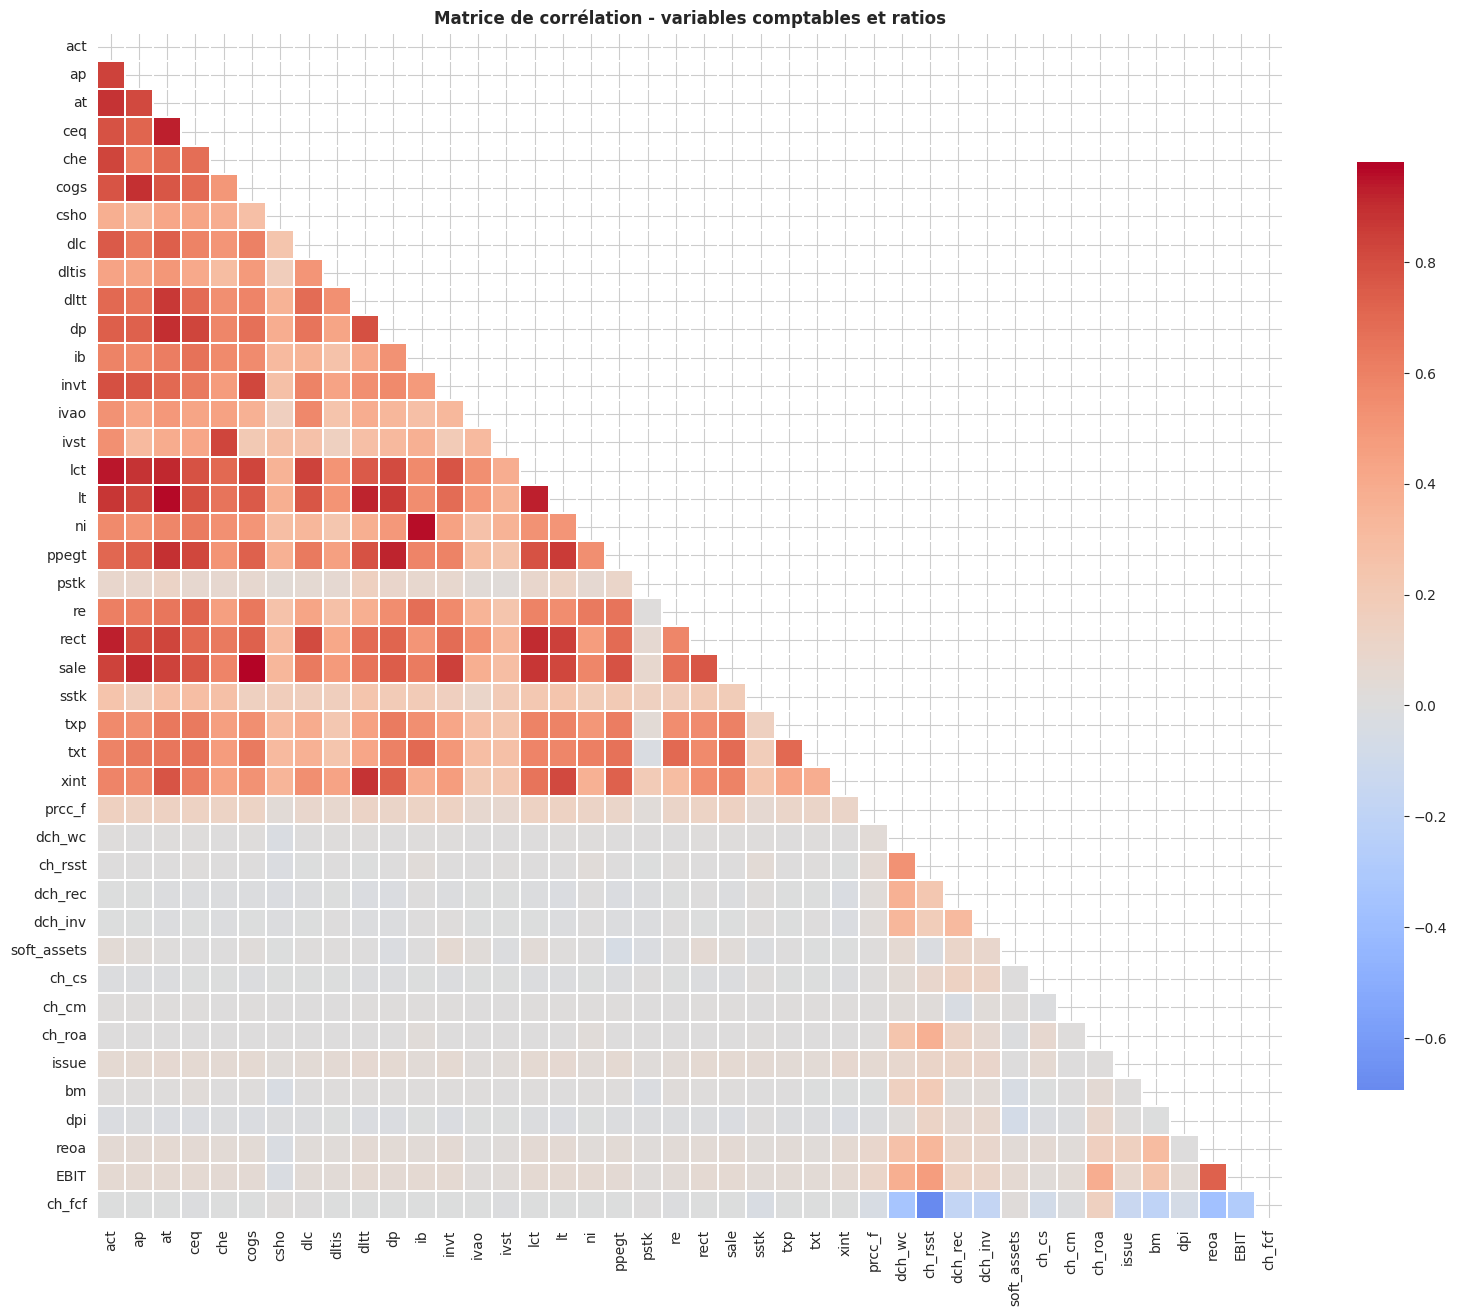

In [16]:
numeric_cols = RAW_ACCOUNTING_VARS + RATIO_VARS
corr = df[numeric_cols].corr()

# Masque le triangle supérieur (redondant avec le triangle inférieur pour une
# matrice symétrique) pour réduire le bruit visuel de la heatmap.
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=False,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Matrice de corrélation - variables comptables et ratios")
fig.tight_layout()
save_fig(fig, "05_correlation_matrix")
plt.show()

In [17]:
from src.config import STRONG_CORRELATION_THRESHOLD

corr_pairs = corr.abs().unstack()
corr_pairs = corr_pairs[corr_pairs < 1].sort_values(ascending=False)
strong_pairs = corr_pairs[corr_pairs > STRONG_CORRELATION_THRESHOLD]

seen = set()
result = []
for (a, b), val in strong_pairs.items():
    if (b, a) not in seen:
        seen.add((a, b))
        result.append((a, b, round(val, 3)))

strong_pairs_df = pd.DataFrame(result, columns=["var_1", "var_2", "correlation"])
print(f"{len(strong_pairs_df)} paires avec |corrélation| > {STRONG_CORRELATION_THRESHOLD}")
strong_pairs_df

23 paires avec |corrélation| > 0.85


,var_1,var_2,correlation
0,sale,cogs,0.981
1,at,lt,0.966
2,ni,ib,0.955
3,lct,act,0.943
4,lct,lt,0.927
5,at,ceq,0.923
6,act,rect,0.922
7,ppegt,dp,0.916
8,dltt,lt,0.915
9,lct,at,0.912


## Synthèse de l'EDA

**Contrôles de qualité** : aucune violation de la clé (`gvkey`, `fyear`), et
les 28 variables comptables brutes sont bien complètes à 100 % comme documenté
— ces deux hypothèses, jusque-là admises sans vérification explicite, sont
maintenant testées par des assertions au lieu d'être supposées.

**Taux de fraude global** : 0,66 % (964 cas de fraude sur 146 045 observations, soit un déséquilibre extrême d'environ 150:1 en faveur des non-fraudes). Ce déséquilibre impose l'usage de métriques adaptées (PR-AUC, Precision@k, Recall, F1) et de techniques de rééquilibrage (class_weight, SMOTE ou RUSBoost) lors de la modélisation — l'accuracy seule serait trompeuse.

**Évolution du taux de fraude dans le temps** : le taux n'est pas stable sur la période 1990-2014. Il est faible dans les années 1990 (~0,3-0,6 %), atteint un pic net entre 1999 et 2003 (jusqu'à 1,27 % en 2000-2001), période coïncidant avec l'éclatement de la bulle internet et les grands scandales comptables (Enron, WorldCom), puis décroît fortement pour atteindre seulement 0,07 % en 2014. Cette baisse récente est probablement un artefact de censure (les fraudes mettent plusieurs années à être détectées et sanctionnées par la SEC) plutôt qu'une baisse réelle — d'où l'importance du split temporel avec gap de 2 ans mis en place dans le feature engineering.

**Colonnes avec valeurs manquantes notables** : `p_aaer` (99,34 % manquant, normal puisque vide par construction pour toute observation non-fraude), et les ratios dérivés `ch_cm` (11,71 %), `ch_cs` (10,90 %), `ch_roa` (8,68 %), `dpi` (6,32 %). Ces NaN sont structurels : les ratios `ch_*`/`dch_*` sont des variations d'une année sur l'autre, donc naturellement absents pour la première année d'observation de chaque entreprise.

**Variables discriminantes (fraude vs non-fraude), confirmées par test de Mann-Whitney U** : les 6 variables testées (`dch_wc`, `soft_assets`, `txp`, `txt`, `EBIT`, `ch_roa`) sont **toutes statistiquement significatives** (p < 0.05) malgré le très petit effectif du groupe fraude (964 observations) — ce n'est donc pas un artefact de lecture des boxplots. `dch_wc` (accruals du fonds de roulement plus positifs chez les fraudeurs), `soft_assets` (plus d'actifs facilement manipulables), `txp`/`txt` (signal directement fiscal) et `EBIT` (rentabilité anormalement plus élevée) restent en tête des tailles d'effet. Ces variables seront probablement en tête de l'importance des features dans les futurs modèles.

**Paires de variables fortement corrélées à surveiller** : voir le tableau ci-dessus, principalement des relations comptables logiques et attendues (`sale` ↔ `cogs`, `at` ↔ `lt`, `ni` ↔ `ib`). Sans impact pour les modèles d'arbres (Random Forest, XGBoost, RUSBoost), mais à traiter par régularisation (Ridge/Lasso) ou sélection de variables en cas d'usage d'une régression logistique.

**Figures sauvegardées** dans `reports/figures/` : distribution de la cible, taux de fraude par année, valeurs manquantes, boxplots fraude vs non-fraude, matrice de corrélation.

**Prochaine étape** : `02_feature_engineering.ipynb`